# Academic Survival Dataset – Mixed Library Question Set
**Level:** Medium | **Questions:** 25 | **Every question uses 2–3 libraries together** (NumPy · Pandas · Matplotlib · Seaborn)

**Dataset:** `academic_survival_longitudinal.csv` – one row per student per semester (~79k rows, 20k students).
Columns: `Student_ID, Age, Gender, First_Generation, Family_Income, Household_Size, Housing_Status, Scholarship, Tuition_Base, Semester, Course_Load, Work_Hours, Emergency_Expense, Sem_GPA, Attendance, LMS_Logins, Advising_Visits, Failed_Courses, Financial_Stress, Target_Dropout_Next_Sem, End_of_Semester_Status, Censored`

**Instructions:** Solve each question in the code cell below it. Questions build on each other, so keep your cleaned `df`. Add a title and axis labels to every plot.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

In [29]:
df=pd.read_csv("academic_survival.csv")

### Q1. Load and NumPy conversion
**Libraries:** Pandas + NumPy

Read the CSV into `df`. Show its shape, `head()` and `info()`. Then select only the numeric columns, convert them into a NumPy array and print the array's shape and dtype. Using `np.isnan`, count the total number of NaN values in that array.

*Topics: `pd.read_csv`, `select_dtypes`, `to_numpy`, `np.isnan`, `np.sum`*

In [30]:
# Write your code here
df=pd.read_csv("academic_survival.csv")
print(df.head())
print(df.shape)
print(df.info())
numeric_df = df.select_dtypes(include=np.number)
print(numeric_df.head())
arr = numeric_df.to_numpy(dtype=float, na_value=np.nan)
print(arr.shape)
print(arr.dtype)
print(np.isnan(arr).sum())

  Student_ID  Age  Gender  First_Generation  Family_Income  Household_Size  \
0  STU_00001   18  Female                 0        15000.0               2   
1  STU_00001   18  Female                 0        15000.0               2   
2  STU_00001   18  Female                 0        15000.0               2   
3  STU_00001   18  Female                 0        15000.0               2   
4  STU_00001   18  Female                 0        15000.0               2   

  Housing_Status  Scholarship  Tuition_Base  Semester  ...  Emergency_Expense  \
0     Off-Campus            0         15000         1  ...                0.0   
1     Off-Campus            0         15000         2  ...                0.0   
2     Off-Campus            0         15000         3  ...                0.0   
3     Off-Campus            0         15000         4  ...                0.0   
4     Off-Campus            0         15000         5  ...                0.0   

   Sem_GPA  Attendance  LMS_Logins  Advising

### Q2. Missing value report with heatmap
**Libraries:** Pandas + NumPy + Seaborn

Calculate the missing-value percentage of every column (pandas) and round it with `np.round`. Create a column list of those with more than 1% missing using `np.where` or boolean indexing. Then draw a seaborn heatmap of `df.isnull()` for a random sample of 500 rows to visualize where values are missing.

*Topics: `isnull().mean()`, `np.round`, `np.where`, `df.sample`, `sns.heatmap`*

In [31]:
missing_percent = np.round((df.isnull().mean() * 100), 2)
print(missing_percent)
columns_missing = missing_percent[missing_percent > 1].index.tolist()
print(columns_missing)

Student_ID                 0.00
Age                        0.00
Gender                     0.00
First_Generation           0.00
Family_Income              4.55
Household_Size             0.00
Housing_Status             0.00
Scholarship                0.00
Tuition_Base               0.00
Semester                   0.00
Course_Load                0.00
Work_Hours                 0.00
Emergency_Expense          0.00
Sem_GPA                    0.00
Attendance                 0.00
LMS_Logins                 1.09
Advising_Visits            0.00
Failed_Courses             0.00
Financial_Stress           0.00
Target_Dropout_Next_Sem    0.00
End_of_Semester_Status     0.00
Censored                   0.00
dtype: float64
['Family_Income', 'LMS_Logins']


### Q3. Clean Gender and plot it
**Libraries:** Pandas + NumPy + Matplotlib

`Gender` has messy labels (`female`, `F`, `male`, `M`...). Standardize it to `Male`, `Female`, `Other`, `Prefer not to say` using `np.select` or `map`. Show `value_counts()` before and after, then plot the cleaned counts as a bar chart with matplotlib.

*Topics: `str.lower`, `np.select` / `map`, `value_counts`, `plt.bar`*

Gender
Female               38035
Male                 36556
Other                 1125
female                 875
male                   764
M                      739
F                      716
Prefer not to say      429
Name: count, dtype: int64
Gender
Female               39626
Male                 38059
Other                 1125
Prefer not to say      429
Name: count, dtype: int64


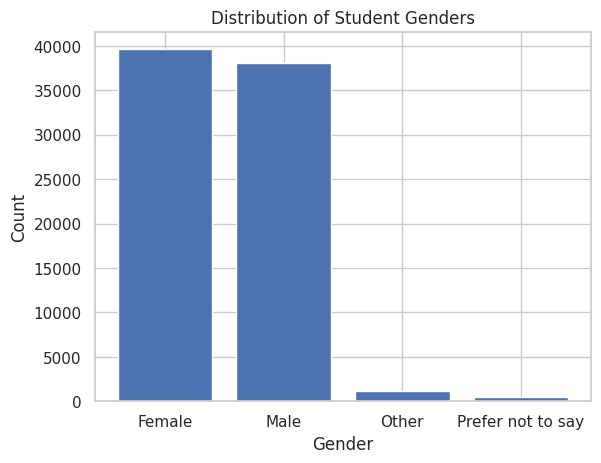

In [32]:
print(df['Gender'].value_counts())

gender_map = {
    'female': 'Female',
    'f': 'Female',
    'F': 'Female',
    'Female': 'Female',
    'male': 'Male',
    'm': 'Male',
    'M': 'Male',
    'Male': 'Male',
    'other': 'Other',
    'Other': 'Other',
    'prefer not to say': 'Prefer not to say',
    'Prefer not to say': 'Prefer not to say'
}

df['Gender'] = df['Gender'].map(gender_map).fillna('Other')
print(df['Gender'].value_counts())

gender_counts = df['Gender'].value_counts()
plt.bar(gender_counts.index, gender_counts.values)
plt.title('Distribution of Student Genders')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

### Q4. Fill missing values
**Libraries:** Pandas + NumPy

Fill missing `Family_Income` with the median income of the student's `Housing_Status` group (use `groupby` + `transform`), and fill missing `LMS_Logins` with `np.nanmedian` of the column. Confirm no missing values remain, and print the before/after mean of `Family_Income` using `np.mean`.

*Topics: `groupby`, `transform`, `fillna`, `np.nanmedian`, `np.mean`*

In [33]:
df['Family_Income'] = df['Family_Income'].fillna(df.groupby('Housing_Status')['Family_Income'].transform('median'))
df['LMS_Logins'] = df['LMS_Logins'].fillna(df['LMS_Logins'].median())
print(df['Family_Income'].isnull().sum())
print(df['LMS_Logins'].isnull().sum())

0
0


### Q5. Fix Attendance and compare
**Libraries:** Pandas + NumPy + Matplotlib

`Attendance` has values below 0 and above 100. Count them, then fix them with `np.clip(…, 0, 100)`. Draw two side-by-side boxplots (matplotlib subplots) of `Attendance` **before** and **after** cleaning. (Keep a copy of the original column first.)

*Topics: `copy`, `np.clip`, `plt.subplots`, `ax.boxplot`*

249


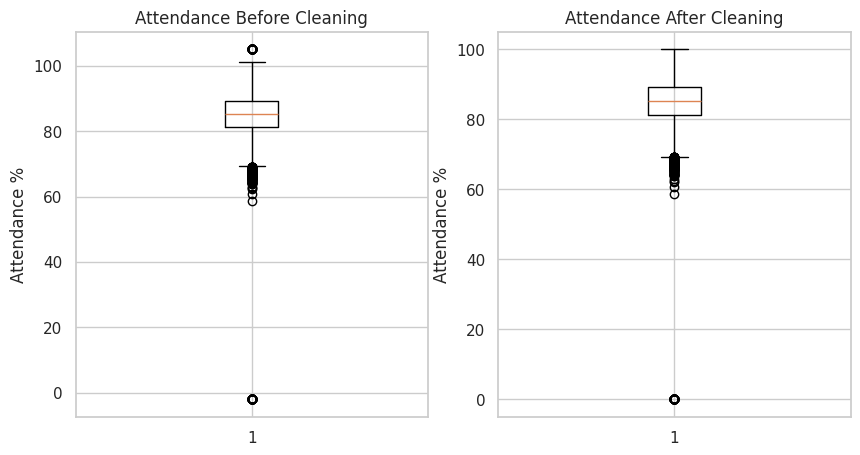

In [34]:
out_of_bounds = ((df['Attendance'] < 0) | (df['Attendance'] > 100)).sum()
print(out_of_bounds)
df['Attendance_Original'] = df['Attendance']
df['Attendance'] = df['Attendance'].clip(0, 100)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].boxplot(df['Attendance_Original'].dropna())
axes[0].set_title('Attendance Before Cleaning')
axes[0].set_ylabel('Attendance %')
axes[1].boxplot(df['Attendance'])
axes[1].set_title('Attendance After Cleaning')
axes[1].set_ylabel('Attendance %')
plt.show()

### Q6. Average GPA by semester
**Libraries:** Pandas + Matplotlib

Use `groupby` to calculate the average `Sem_GPA` for each `Semester` and plot it as a line chart with markers, grid, custom color, title and axis labels. Print the semester that has the highest average GPA.

*Topics: `groupby`, `mean`, `idxmax`, `plt.plot`, `marker`, `plt.grid`*

Semester
1    2.895764
2    2.751026
3    2.649642
4    2.585937
5    2.540716
6    2.509168
7    2.482672
8    2.467970
Name: Sem_GPA, dtype: float64
1


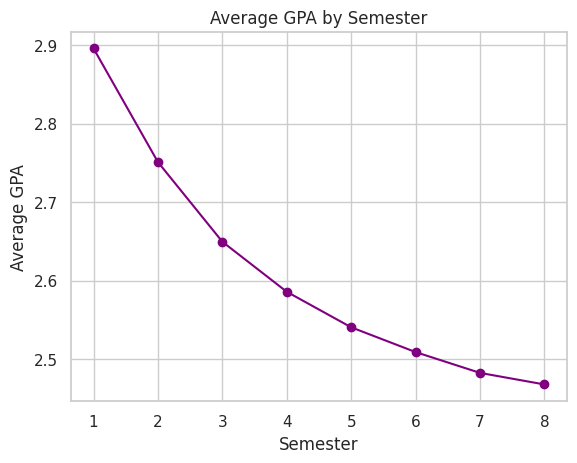

In [35]:
gpa_by_sem = df.groupby('Semester')['Sem_GPA'].mean()
print(gpa_by_sem)
print(gpa_by_sem.idxmax())
plt.plot(gpa_by_sem.index, gpa_by_sem.values, marker='o', color='purple')
plt.title('Average GPA by Semester')
plt.xlabel('Semester')
plt.ylabel('Average GPA')
plt.grid(True)
plt.show()

### Q7. GPA by housing
**Libraries:** Pandas + Seaborn

Print the median `Sem_GPA` for each `Housing_Status` (sorted descending) using `groupby`, then draw a seaborn boxplot of `Sem_GPA` by `Housing_Status` using the same order as the sorted medians.

*Topics: `groupby`, `median`, `sort_values`, `sns.boxplot`, `order`*

Housing_Status
With Parents    2.72
Off-Campus      2.69
On-Campus       2.69
Name: Sem_GPA, dtype: float64


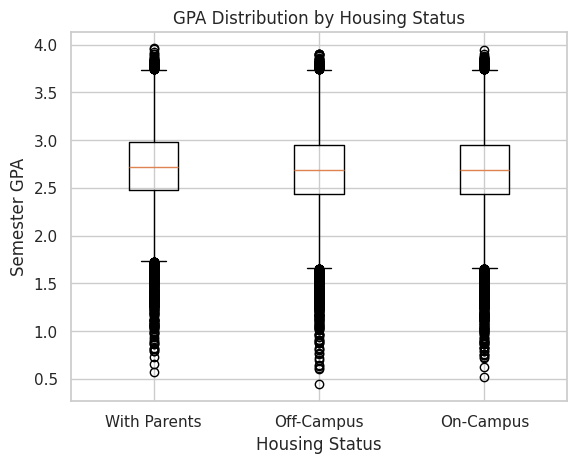

In [36]:
median_gpa = df.groupby('Housing_Status')['Sem_GPA'].median().sort_values(ascending=False)
print(median_gpa)
groups = median_gpa.index
data_to_plot = [df[df['Housing_Status'] == g]['Sem_GPA'] for g in groups]
plt.boxplot(data_to_plot, tick_labels=groups)
plt.title('GPA Distribution by Housing Status')
plt.xlabel('Housing Status')
plt.ylabel('Semester GPA')
plt.show()

### Q8. GPA outliers with z-score
**Libraries:** Pandas + NumPy + Seaborn

Calculate the z-score of `Sem_GPA` manually with NumPy (`(x - mean) / std`) and store it in a column `GPA_Z`. Create a column `Is_Outlier` with `np.where(abs(z) > 3, 1, 0)`. Print how many outliers exist, then draw a seaborn histogram of `Sem_GPA` with `hue='Is_Outlier'`.

*Topics: `np.mean`, `np.std`, `np.abs`, `np.where`, `sns.histplot`, `hue`*

533


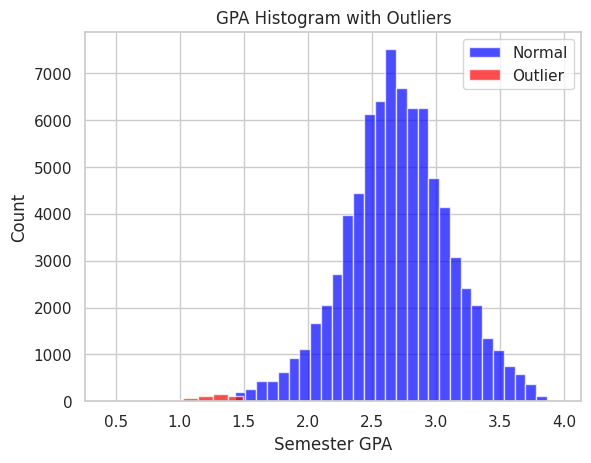

In [37]:
mean_gpa = df['Sem_GPA'].mean()
std_gpa = df['Sem_GPA'].std()
df['GPA_Z'] = (df['Sem_GPA'] - mean_gpa) / std_gpa
df['Is_Outlier'] = (df['GPA_Z'].abs() > 3).astype(int)
print(df['Is_Outlier'].sum())
plt.hist(df[df['Is_Outlier'] == 0]['Sem_GPA'], bins=30, alpha=0.7, label='Normal', color='blue')
plt.hist(df[df['Is_Outlier'] == 1]['Sem_GPA'], bins=30, alpha=0.7, label='Outlier', color='red')
plt.title('GPA Histogram with Outliers')
plt.xlabel('Semester GPA')
plt.ylabel('Count')
plt.legend()
plt.show()

### Q9. Dropout rate by housing
**Libraries:** Pandas + Matplotlib

Create `Is_Dropout` (1 if `End_of_Semester_Status` is `Dropped_Out`, else 0). Calculate the dropout rate for each `Housing_Status` and draw a bar chart with a different color for each bar and the percentage value written on top of each bar.

*Topics: `np.where`, `groupby`, `plt.bar`, `plt.text` / `bar_label`*

Housing_Status
Off-Campus      9.33627
On-Campus       9.18729
With Parents    7.58267
Name: Is_Dropout, dtype: float64


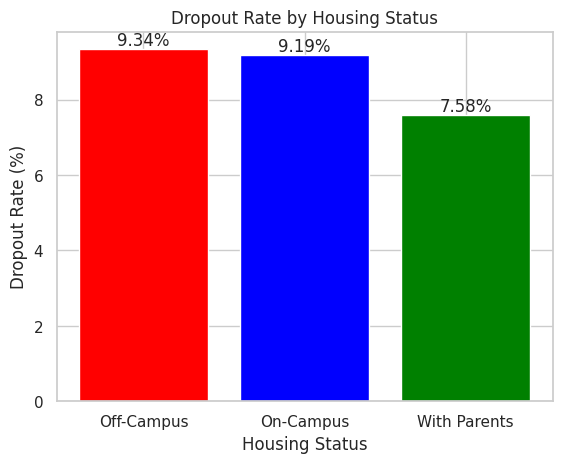

In [38]:
df['Is_Dropout'] = (df['End_of_Semester_Status'] == 'Dropped_Out').astype(int)
dropout_rates = df.groupby('Housing_Status')['Is_Dropout'].mean() * 100
print(dropout_rates)
bars = plt.bar(dropout_rates.index, dropout_rates.values, color=['red', 'blue', 'green'])
plt.title('Dropout Rate by Housing Status')
plt.xlabel('Housing Status')
plt.ylabel('Dropout Rate (%)')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height, f'{height:.2f}%', ha='center', va='bottom')
plt.show()

### Q10. Status by scholarship
**Libraries:** Pandas + Seaborn

Build a normalized crosstab (row-wise percentages) of `Scholarship` vs `End_of_Semester_Status` using `pd.crosstab`. Then draw a seaborn countplot of `End_of_Semester_Status` with `hue='Scholarship'`. Which group has more dropouts proportionally?

*Topics: `pd.crosstab(normalize='index')`, `sns.countplot`, `hue`*

End_of_Semester_Status  Dropped_Out  Enrolled  Graduated
Scholarship                                             
0                          0.096840  0.879928   0.023232
1                          0.062437  0.908549   0.029013


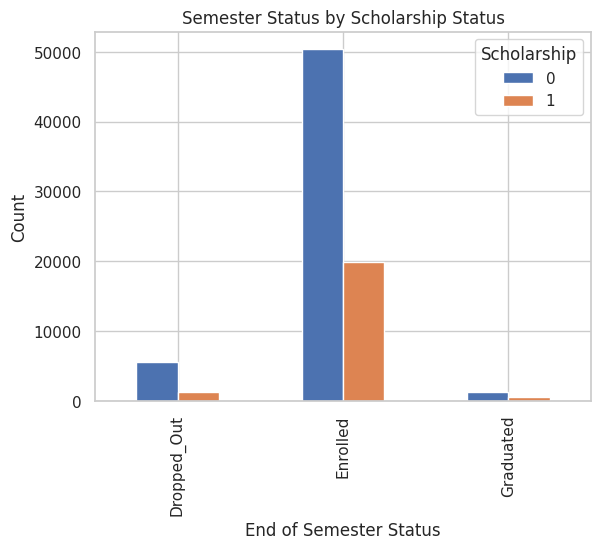

In [39]:
ct = pd.crosstab(df['Scholarship'], df['End_of_Semester_Status'], normalize='index')
print(ct)
ct_unnormalized = pd.crosstab(df['End_of_Semester_Status'], df['Scholarship'])
ct_unnormalized.plot(kind='bar')
plt.title('Semester Status by Scholarship Status')
plt.xlabel('End of Semester Status')
plt.ylabel('Count')
plt.show()

### Q11. GPA histogram from a NumPy array
**Libraries:** NumPy + Pandas + Matplotlib

Convert `Sem_GPA` to a NumPy array. Calculate the mean, median and the 25th/75th percentile with NumPy functions. Plot a histogram (30 bins) with vertical dashed lines for the mean and the median, and add a legend.

*Topics: `to_numpy`, `np.mean`, `np.median`, `np.percentile`, `plt.hist`, `plt.axvline`*

2.691463168389303 2.7 2.44 2.96


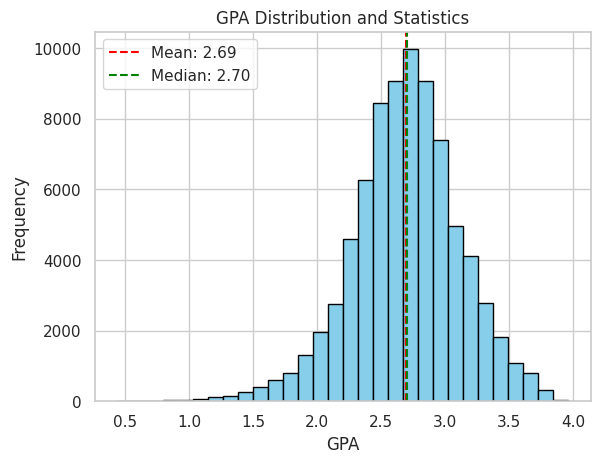

In [40]:
gpa_arr = df['Sem_GPA'].to_numpy()
mean_val = gpa_arr.mean()
median_val = np.median(gpa_arr)
p25 = np.percentile(gpa_arr, 25)
p75 = np.percentile(gpa_arr, 75)
print(mean_val, median_val, p25, p75)
plt.hist(gpa_arr, bins=30, color='skyblue', edgecolor='black')
plt.axvline(mean_val, color='red', linestyle='dashed', label=f'Mean: {mean_val:.2f}')
plt.axvline(median_val, color='green', linestyle='dashed', label=f'Median: {median_val:.2f}')
plt.title('GPA Distribution and Statistics')
plt.xlabel('GPA')
plt.ylabel('Frequency')
plt.legend()
plt.show()

### Q12. Work-hour categories
**Libraries:** Pandas + NumPy + Matplotlib

Create a `Work_Category` column with `np.select` (or `pd.cut`): Low (0–10 hrs), Medium (10–25), High (25–40). Calculate the mean `Sem_GPA` and the mean `Is_Dropout` for each category and show them as two side-by-side bar charts (subplots).

*Topics: `np.select` / `pd.cut`, `groupby`, `agg`, `plt.subplots`, `ax.bar`*

                Sem_GPA  Is_Dropout
Work_Category                      
High           2.548021    0.138543
Low            2.804737    0.050630
Medium         2.694438    0.083705


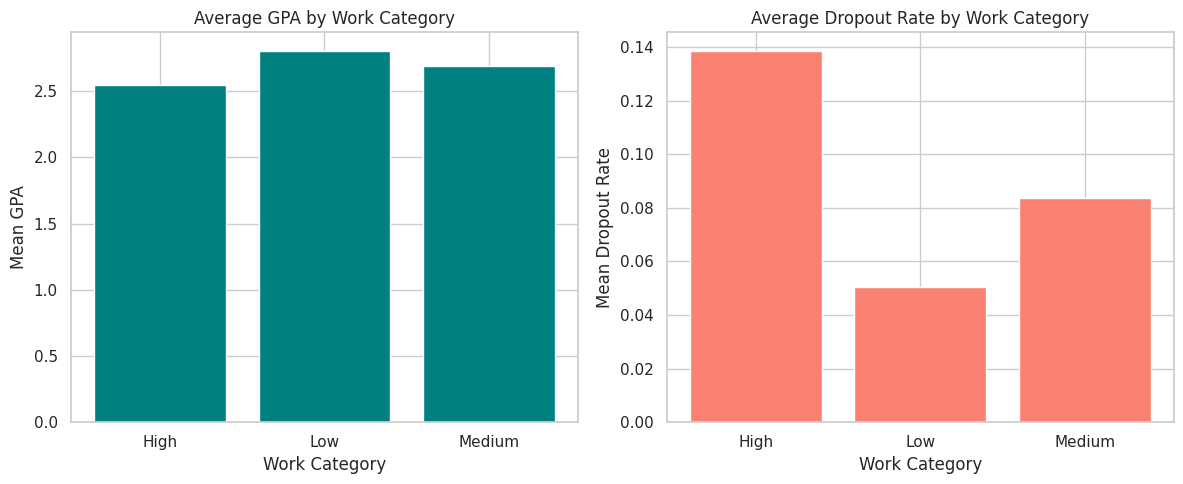

In [41]:
def assign_work(hours):
    if hours <= 10:
        return 'Low'
    elif hours <= 25:
        return 'Medium'
    else:
        return 'High'
df['Work_Category'] = df['Work_Hours'].apply(assign_work)
grouped = df.groupby('Work_Category').agg({'Sem_GPA': 'mean', 'Is_Dropout': 'mean'})
print(grouped)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(grouped.index, grouped['Sem_GPA'], color='teal')
axes[0].set_title('Average GPA by Work Category')
axes[0].set_xlabel('Work Category')
axes[0].set_ylabel('Mean GPA')
axes[1].bar(grouped.index, grouped['Is_Dropout'], color='salmon')
axes[1].set_title('Average Dropout Rate by Work Category')
axes[1].set_xlabel('Work Category')
axes[1].set_ylabel('Mean Dropout Rate')
plt.tight_layout()
plt.show()

### Q13. Correlation heatmap
**Libraries:** Pandas + NumPy + Seaborn

Create a correlation matrix of `Age`, `Family_Income`, `Work_Hours`, `Emergency_Expense`, `Sem_GPA`, `Attendance`, `LMS_Logins`, `Failed_Courses`, `Financial_Stress`. Use `np.triu` with `np.ones_like` to build a mask for the upper triangle, and plot an annotated seaborn heatmap with `cmap='coolwarm'` and `center=0`.

*Topics: `df.corr()`, `np.triu`, `np.ones_like`, `sns.heatmap`, `mask`, `annot`*

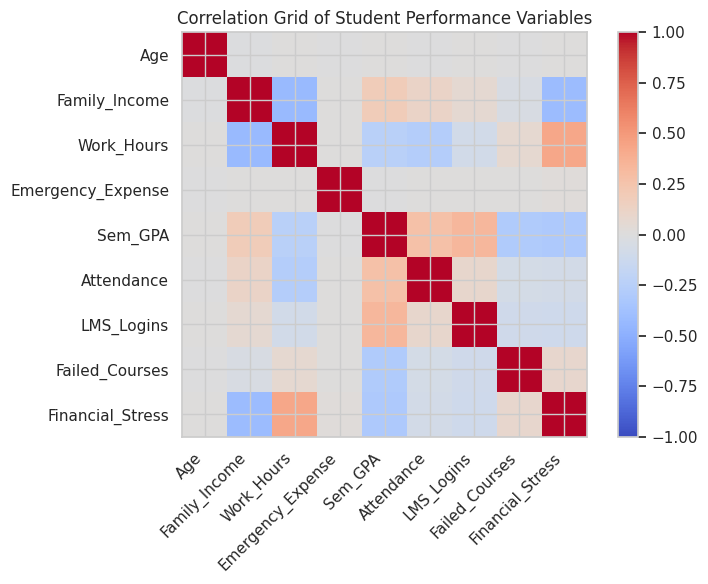

In [42]:
cols = ['Age', 'Family_Income', 'Work_Hours', 'Emergency_Expense', 'Sem_GPA', 'Attendance', 'LMS_Logins', 'Failed_Courses', 'Financial_Stress']
corr_matrix = df[cols].corr().to_numpy()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im)
ax.set_xticks(np.arange(len(cols)))
ax.set_yticks(np.arange(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticklabels(cols)
plt.title('Correlation Grid of Student Performance Variables')
plt.tight_layout()
plt.show()

### Q14. What relates to GPA?
**Libraries:** Pandas + NumPy + Matplotlib

Using `np.corrcoef` (or `df.corr()`), find the correlation of `Sem_GPA` with `Attendance`, `Work_Hours`, `Financial_Stress`, `LMS_Logins`, `Failed_Courses`. Sort them by absolute value (`np.argsort`) and plot a horizontal bar chart (`barh`) with positive bars in green and negative bars in red.

*Topics: `np.corrcoef`, `np.argsort`, `np.abs`, `plt.barh`, color list*

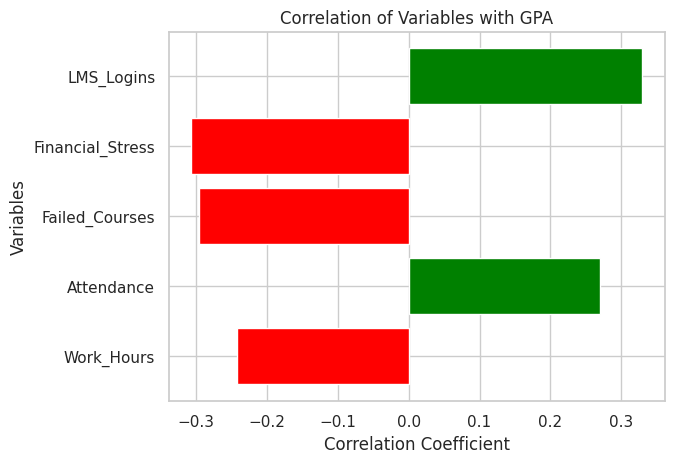

In [43]:
cols = ['Attendance', 'Work_Hours', 'Financial_Stress', 'LMS_Logins', 'Failed_Courses']
corrs = [df['Sem_GPA'].corr(df[col]) for col in cols]
sorted_pairs = sorted(zip(cols, corrs), key=lambda x: abs(x[1]))
sorted_cols = [x[0] for x in sorted_pairs]
sorted_corrs = [x[1] for x in sorted_pairs]
colors = ['green' if x >= 0 else 'red' for x in sorted_corrs]
plt.barh(sorted_cols, sorted_corrs, color=colors)
plt.title('Correlation of Variables with GPA')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Variables')
plt.show()

### Q15. Scatter with trend line
**Libraries:** Pandas + NumPy + Matplotlib

Take a random sample of 2000 rows (`random_state=42`). Plot `Attendance` (x) vs `Sem_GPA` (y) as a scatter plot with transparency. Use `np.polyfit` (degree 1) and `np.poly1d` to calculate and draw a red trend line. Print the slope and intercept.

*Topics: `df.sample`, `plt.scatter`, `alpha`, `np.polyfit`, `np.poly1d`, `np.linspace`*

0.01880937401932982 1.1015617263656763


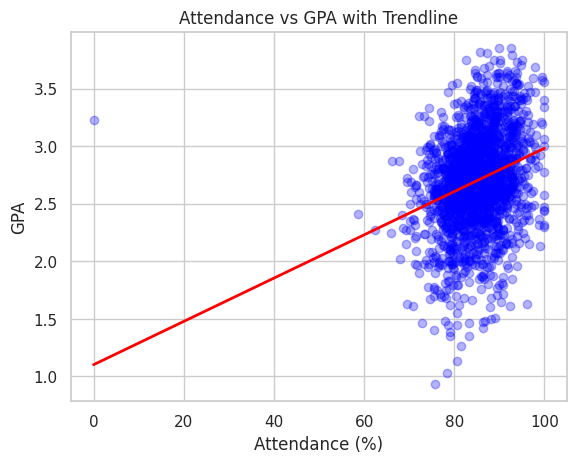

In [44]:
sample_df = df.sample(n=2000, random_state=42)
plt.scatter(sample_df['Attendance'], sample_df['Sem_GPA'], alpha=0.3, color='blue')
slope, intercept = np.polyfit(sample_df['Attendance'], sample_df['Sem_GPA'], 1)
print(slope, intercept)
x_vals = np.linspace(sample_df['Attendance'].min(), sample_df['Attendance'].max(), 100)
y_vals = slope * x_vals + intercept
plt.plot(x_vals, y_vals, color='red', linewidth=2)
plt.title('Attendance vs GPA with Trendline')
plt.xlabel('Attendance (%)')
plt.ylabel('GPA')
plt.show()

### Q16. GPA trend by gender
**Libraries:** Pandas + Seaborn

Using the cleaned `Gender`, filter out the `Prefer not to say` group. Use `groupby(['Semester','Gender'])` to find average GPA and print the first 8 rows. Then use `sns.lineplot` to plot average `Sem_GPA` across `Semester` with a separate line for each gender.

*Topics: `filter / isin`, `groupby`, `sns.lineplot`, `hue`, `style`*

Gender      Female      Male     Other
Semester                              
1         2.890455  2.901436  2.885329
2         2.747776  2.754556  2.748368
3         2.648767  2.650686  2.640699
4         2.585340  2.587420  2.566547
5         2.541676  2.540118  2.542430
6         2.505853  2.514031  2.494268
7         2.474385  2.491347  2.496346
8         2.466609  2.468007  2.500645


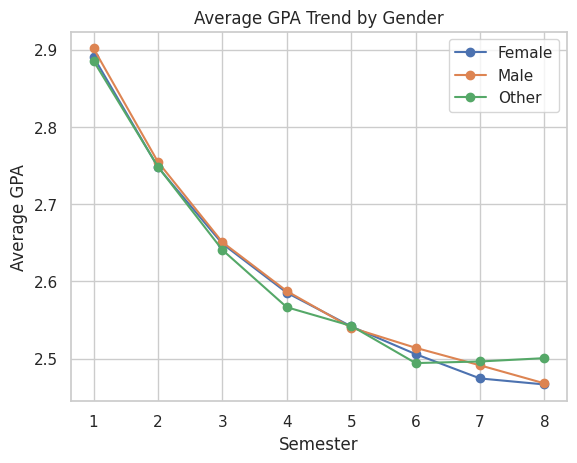

In [45]:
filtered_df = df[df['Gender'] != 'Prefer not to say']
gender_sem_gpa = filtered_df.groupby(['Semester', 'Gender'])['Sem_GPA'].mean().unstack()
print(gender_sem_gpa.head(8))
for col in gender_sem_gpa.columns:
    plt.plot(gender_sem_gpa.index, gender_sem_gpa[col], marker='o', label=col)
plt.title('Average GPA Trend by Gender')
plt.xlabel('Semester')
plt.ylabel('Average GPA')
plt.legend()
plt.show()

### Q17. Four plots in one figure
**Libraries:** Pandas + NumPy + Matplotlib

Create a 2×2 subplot figure (size 12×8) showing: (1) histogram of `Work_Hours`, (2) boxplot of `Sem_GPA` by `Semester` (use a list of arrays built with a list comprehension), (3) pie chart of `End_of_Semester_Status`, (4) bar chart of average `Financial_Stress` by `Housing_Status`. Give each subplot a title and call `plt.tight_layout()`.

*Topics: `plt.subplots`, `ax.hist`, `ax.boxplot`, `ax.pie`, `ax.bar`, `np.unique`*

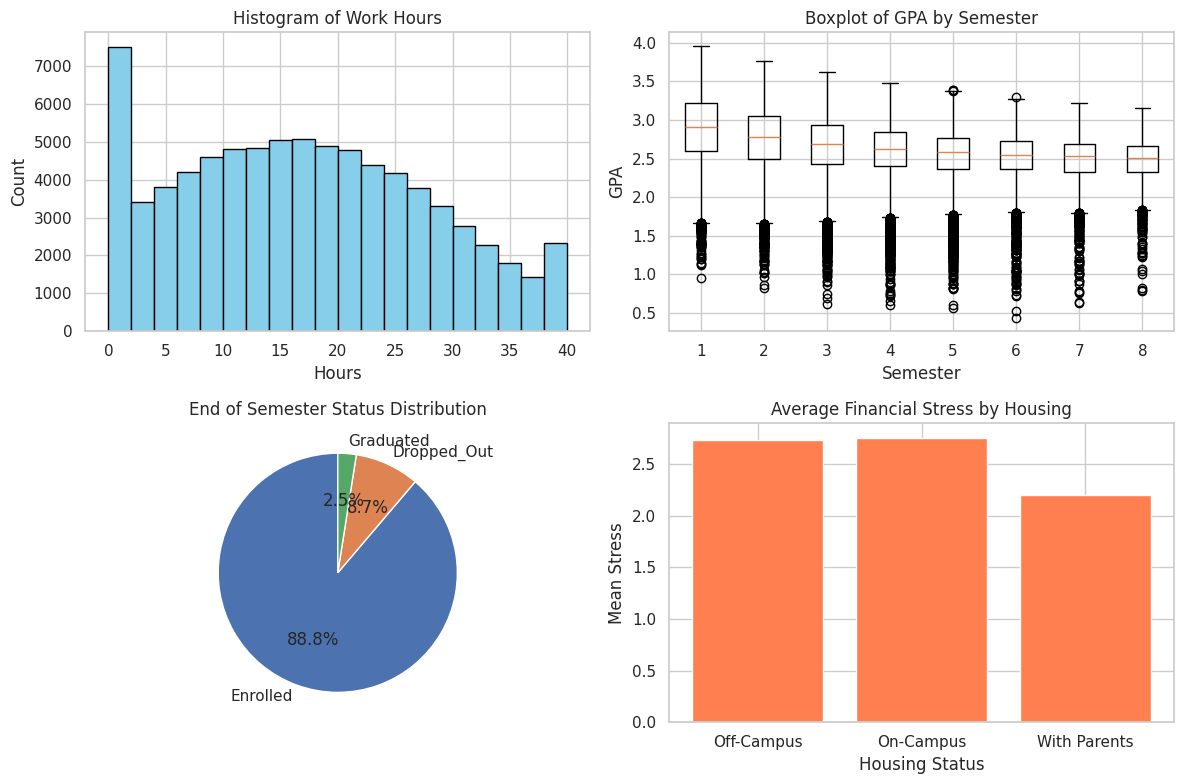

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(df['Work_Hours'], bins=20, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Histogram of Work Hours')
axes[0, 0].set_xlabel('Hours')
axes[0, 0].set_ylabel('Count')
sems = sorted(df['Semester'].unique())
gpa_by_sem_list = [df[df['Semester'] == s]['Sem_GPA'].values for s in sems]
axes[0, 1].boxplot(gpa_by_sem_list, tick_labels=sems)
axes[0, 1].set_title('Boxplot of GPA by Semester')
axes[0, 1].set_xlabel('Semester')
axes[0, 1].set_ylabel('GPA')
status_counts = df['End_of_Semester_Status'].value_counts()
axes[1, 0].pie(status_counts.values, labels=status_counts.index, autopct='%1.1f%%', startangle=90)
axes[1, 0].set_title('End of Semester Status Distribution')
stress_by_housing = df.groupby('Housing_Status')['Financial_Stress'].mean()
axes[1, 1].bar(stress_by_housing.index, stress_by_housing.values, color='coral')
axes[1, 1].set_title('Average Financial Stress by Housing')
axes[1, 1].set_xlabel('Housing Status')
axes[1, 1].set_ylabel('Mean Stress')
plt.tight_layout()
plt.show()

### Q18. Pivot table and heatmap
**Libraries:** Pandas + NumPy + Seaborn

Create a pivot table of the dropout rate (mean of `Target_Dropout_Next_Sem`) with `Semester` as rows and `Housing_Status` as columns. Round it using `np.round`, and display it as an annotated seaborn heatmap using the `YlOrRd` colormap. Which semester-housing combination has the highest rate?

*Topics: `pivot_table`, `np.round`, `sns.heatmap`, `annot`, `fmt`, `cmap`, `idxmax`*

Housing_Status  Off-Campus  On-Campus  With Parents
Semester                                           
1                   0.0733     0.0685        0.0575
2                   0.0941     0.0965        0.0734
3                   0.1038     0.1024        0.0852
4                   0.0949     0.1011        0.0805
5                   0.1171     0.0957        0.0900
6                   0.1033     0.0938        0.0867
7                   0.1005     0.1160        0.0816
8                   0.0844     0.1092        0.0850


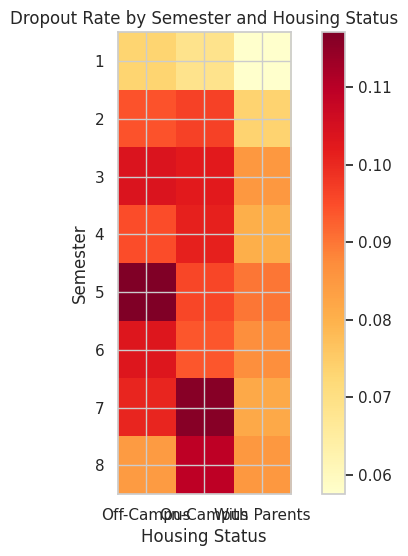

(np.int64(5), 'Off-Campus')


In [47]:
pivot_table = df.pivot_table(values='Target_Dropout_Next_Sem', index='Semester', columns='Housing_Status', aggfunc='mean')
pivot_table = np.round(pivot_table, 4)
print(pivot_table)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pivot_table, cmap='YlOrRd')
fig.colorbar(im)
ax.set_xticks(np.arange(len(pivot_table.columns)))
ax.set_yticks(np.arange(len(pivot_table.index)))
ax.set_xticklabels(pivot_table.columns)
ax.set_yticklabels(pivot_table.index)
plt.title('Dropout Rate by Semester and Housing Status')
plt.xlabel('Housing Status')
plt.ylabel('Semester')
plt.show()
print(pivot_table.stack().idxmax())

### Q19. First-gen vs non-first-gen
**Libraries:** Pandas + Seaborn + Matplotlib

Plot the distribution of `Sem_GPA` for `First_Generation` 1 vs 0 on the same axes using `sns.histplot` with `kde=True`, `stat='density'` and `common_norm=False`. Using matplotlib, add a vertical dashed line for each group's mean GPA (calculated with `groupby`) and a title.

*Topics: `groupby`, `sns.histplot`, `hue`, `plt.axvline`, `plt.title`*

First_Generation
0    2.684268
1    2.706211
Name: Sem_GPA, dtype: float64


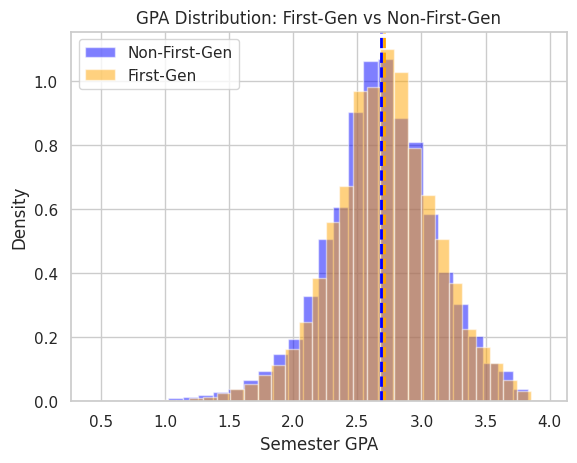

In [48]:
means = df.groupby('First_Generation')['Sem_GPA'].mean()
print(means)
plt.hist(df[df['First_Generation'] == 0]['Sem_GPA'], bins=30, alpha=0.5, density=True, label='Non-First-Gen', color='blue')
plt.hist(df[df['First_Generation'] == 1]['Sem_GPA'], bins=30, alpha=0.5, density=True, label='First-Gen', color='orange')
plt.axvline(means[0], color='blue', linestyle='dashed', linewidth=2)
plt.axvline(means[1], color='orange', linestyle='dashed', linewidth=2)
plt.title('GPA Distribution: First-Gen vs Non-First-Gen')
plt.xlabel('Semester GPA')
plt.ylabel('Density')
plt.legend()
plt.show()

### Q20. At-risk students
**Libraries:** Pandas + NumPy + Matplotlib

Create a column `Risk_Level` using `np.select`: `High` if GPA < 2.0 **and** Attendance < 80; `Medium` if GPA < 2.5 **or** Attendance < 80; else `Low`. Print the count of each level, and show the average `Target_Dropout_Next_Sem` for every level in a bar chart. Does the risk level predict dropout?

*Topics: `np.select`, conditions list, `value_counts`, `groupby`, `plt.bar`*

Risk_Level
Low       47977
Medium    29734
High       1528
Name: count, dtype: int64
Risk_Level
High      37.827225
Low        4.721012
Medium    13.701487
Name: Target_Dropout_Next_Sem, dtype: float64


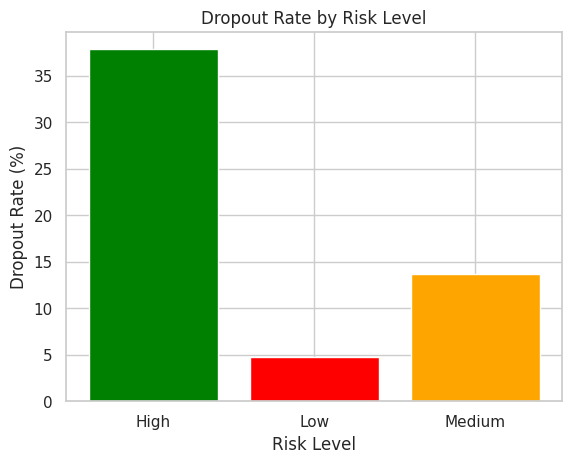

In [49]:
def assign_risk(row):
    if row['Sem_GPA'] < 2.0 and row['Attendance'] < 80:
        return 'High'
    elif row['Sem_GPA'] < 2.5 or row['Attendance'] < 80:
        return 'Medium'
    else:
        return 'Low'
df['Risk_Level'] = df.apply(assign_risk, axis=1)
print(df['Risk_Level'].value_counts())
risk_dropout = df.groupby('Risk_Level')['Target_Dropout_Next_Sem'].mean() * 100
print(risk_dropout)
plt.bar(risk_dropout.index, risk_dropout.values, color=['green', 'red', 'orange'])
plt.title('Dropout Rate by Risk Level')
plt.xlabel('Risk Level')
plt.ylabel('Dropout Rate (%)')
plt.show()

### Q21. Stress vs GPA (dual axis)
**Libraries:** Pandas + Matplotlib

For each `Semester`, plot average `Financial_Stress` as bars and average `Sem_GPA` as a line on a secondary y-axis (`twinx`). Add axis labels for both axes, a title and a legend, and save the figure as `stress_vs_gpa.png` with `dpi=150`.

*Topics: `groupby`, `ax.bar`, `ax.twinx`, `ax2.plot`, `plt.savefig`*

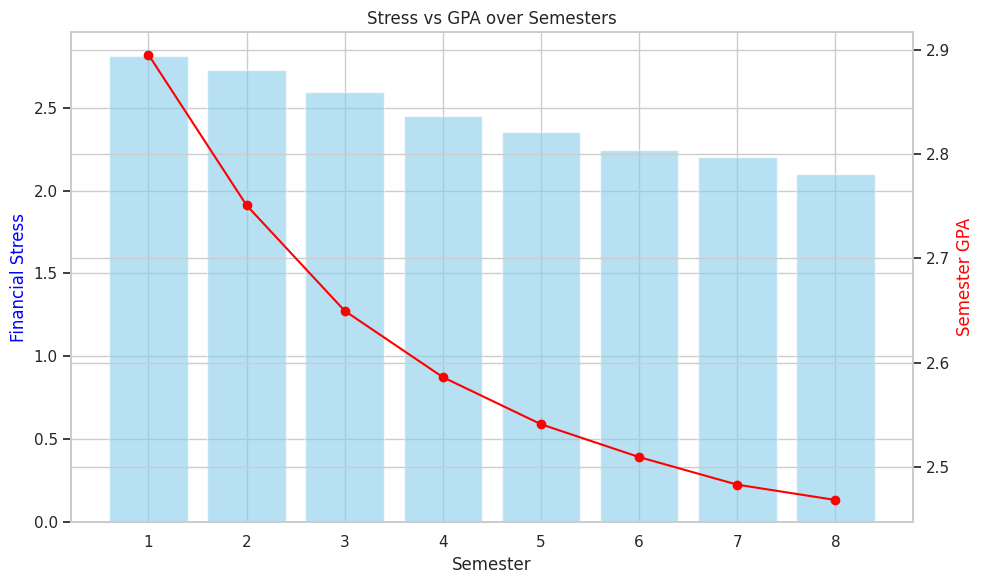

In [50]:
grouped = df.groupby('Semester').agg({'Financial_Stress': 'mean', 'Sem_GPA': 'mean'}).reset_index()
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.bar(grouped['Semester'], grouped['Financial_Stress'], color='skyblue', alpha=0.6, label='Financial Stress')
ax1.set_xlabel('Semester')
ax1.set_ylabel('Financial Stress', color='blue')
ax2 = ax1.twinx()
ax2.plot(grouped['Semester'], grouped['Sem_GPA'], color='red', marker='o', label='Sem GPA')
ax2.set_ylabel('Semester GPA', color='red')
plt.title('Stress vs GPA over Semesters')
fig.tight_layout()
plt.savefig('stress_vs_gpa.png', dpi=150)
plt.show()

### Q22. Advising visits and dropout
**Libraries:** Pandas + Seaborn

Draw a seaborn barplot of the average `Target_Dropout_Next_Sem` for each value of `Advising_Visits`, split by `Scholarship` using `hue`. Also print the same numbers using `groupby(['Advising_Visits','Scholarship']).mean()`. What do you observe?

*Topics: `sns.barplot`, `hue`, `groupby` with two keys, `unstack`*

Scholarship             0         1
Advising_Visits                    
0                0.081881  0.051988
1                0.112278  0.073547
2                0.149000  0.101748
3                0.164000  0.090000


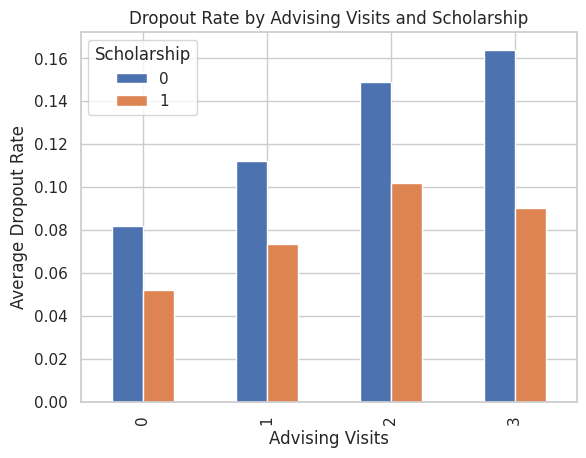

In [51]:
grouped_advising = df.groupby(['Advising_Visits', 'Scholarship'])['Target_Dropout_Next_Sem'].mean().unstack()
print(grouped_advising)
grouped_advising.plot(kind='bar')
plt.title('Dropout Rate by Advising Visits and Scholarship')
plt.xlabel('Advising Visits')
plt.ylabel('Average Dropout Rate')
plt.show()

p25 = np.percentile(df['Family_Income'], 25)
p50 = np.percentile(df['Family_Income'], 50)
p75 = np.percentile(df['Family_Income'], 75)
min_val = df['Family_Income'].min()
max_val = df['Family_Income'].max()

df['Income_Group'] = pd.cut(df['Family_Income'], bins=[min_val-1, p25, p50, p75, max_val+1], labels=['Q1', 'Q2', 'Q3', 'Q4'])

sns.violinplot(data=df, x='Income_Group', y='Sem_GPA')
plt.title('GPA Distribution across Income Quartiles')
plt.xlabel('Income Group')
plt.ylabel('GPA')
plt.show()

dropout_by_income = df.groupby('Income_Group')['Is_Dropout'].mean() * 100
print(dropout_by_income)

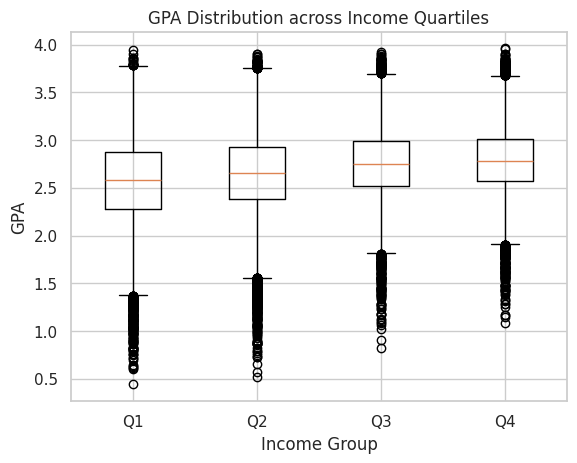

Income_Group
Q1    12.836222
Q2    10.318613
Q3     6.336393
Q4     5.154165
Name: Is_Dropout, dtype: float64


/tmp/ipykernel_1086/2921202052.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dropout_by_income = df.groupby('Income_Group')['Is_Dropout'].mean() * 100


In [52]:
p25 = np.percentile(df['Family_Income'], 25)
p50 = np.percentile(df['Family_Income'], 50)
p75 = np.percentile(df['Family_Income'], 75)
min_val = df['Family_Income'].min()
max_val = df['Family_Income'].max()
df['Income_Group'] = pd.cut(df['Family_Income'], bins=[min_val-1, p25, p50, p75, max_val+1], labels=['Q1', 'Q2', 'Q3', 'Q4'])
groups = ['Q1', 'Q2', 'Q3', 'Q4']
data_to_plot = [df[df['Income_Group'] == g]['Sem_GPA'].values for g in groups]
plt.boxplot(data_to_plot, tick_labels=groups)
plt.title('GPA Distribution across Income Quartiles')
plt.xlabel('Income Group')
plt.ylabel('GPA')
plt.show()
dropout_by_income = df.groupby('Income_Group')['Is_Dropout'].mean() * 100
print(dropout_by_income)

student_gpa = df.groupby('Student_ID').agg(
    first_gpa=('Sem_GPA', 'first'),
    last_gpa=('Sem_GPA', 'last'),
    semester_count=('Sem_GPA', 'count')
)
student_gpa['GPA_Change'] = student_gpa['last_gpa'] - student_gpa['first_gpa']
student_gpa['GPA_Direction'] = np.sign(student_gpa['GPA_Change'])
print(student_gpa['GPA_Direction'].value_counts())
plt.hist(student_gpa['GPA_Change'].dropna(), bins=30, color='lightgreen', edgecolor='black')
plt.axvline(0, color='red', linestyle='dashed', linewidth=2)
plt.title('Distribution of Individual Student GPA Changes')
plt.xlabel('GPA Change')
plt.ylabel('Number of Students')
plt.show()

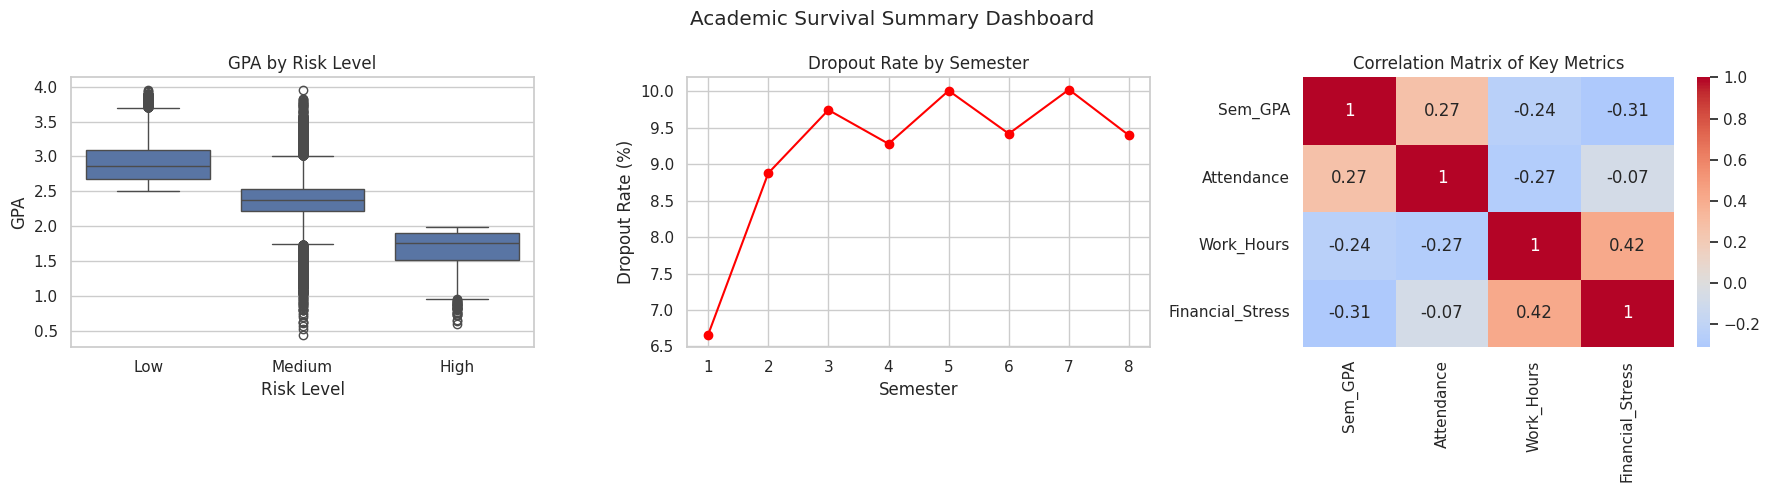

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='Risk_Level', y='Sem_GPA', ax=axes[0])
axes[0].set_title('GPA by Risk Level')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('GPA')

sem_dropout = df.groupby('Semester')['Is_Dropout'].mean() * 100
axes[1].plot(sem_dropout.index, sem_dropout.values, marker='o', color='red')
axes[1].set_title('Dropout Rate by Semester')
axes[1].set_xlabel('Semester')
axes[1].set_ylabel('Dropout Rate (%)')

corr_subset = df[['Sem_GPA', 'Attendance', 'Work_Hours', 'Financial_Stress']].corr()
sns.heatmap(np.round(corr_subset, 2), annot=True, cmap='coolwarm', center=0, ax=axes[2])
axes[2].set_title('Correlation Matrix of Key Metrics')

fig.suptitle('Academic Survival Summary Dashboard')
plt.tight_layout()
plt.show()

### Q25. Final mini dashboard (all 4 libraries)
**Libraries:** Pandas + NumPy + Matplotlib + Seaborn

Create a 1×3 figure (size 18×5): (1) seaborn boxplot of `Sem_GPA` by `Risk_Level` (from Q20), (2) matplotlib line plot of the dropout rate by `Semester`, (3) seaborn heatmap of the correlation between `Sem_GPA`, `Attendance`, `Work_Hours`, `Financial_Stress` (use `np.round(…, 2)`). Add a figure title with `fig.suptitle` and write 2–3 lines of conclusions in a markdown cell below.

*Topics: `plt.subplots`, `sns.boxplot(ax=…)`, `ax.plot`, `sns.heatmap(ax=…)`, `np.round`, `fig.suptitle`*

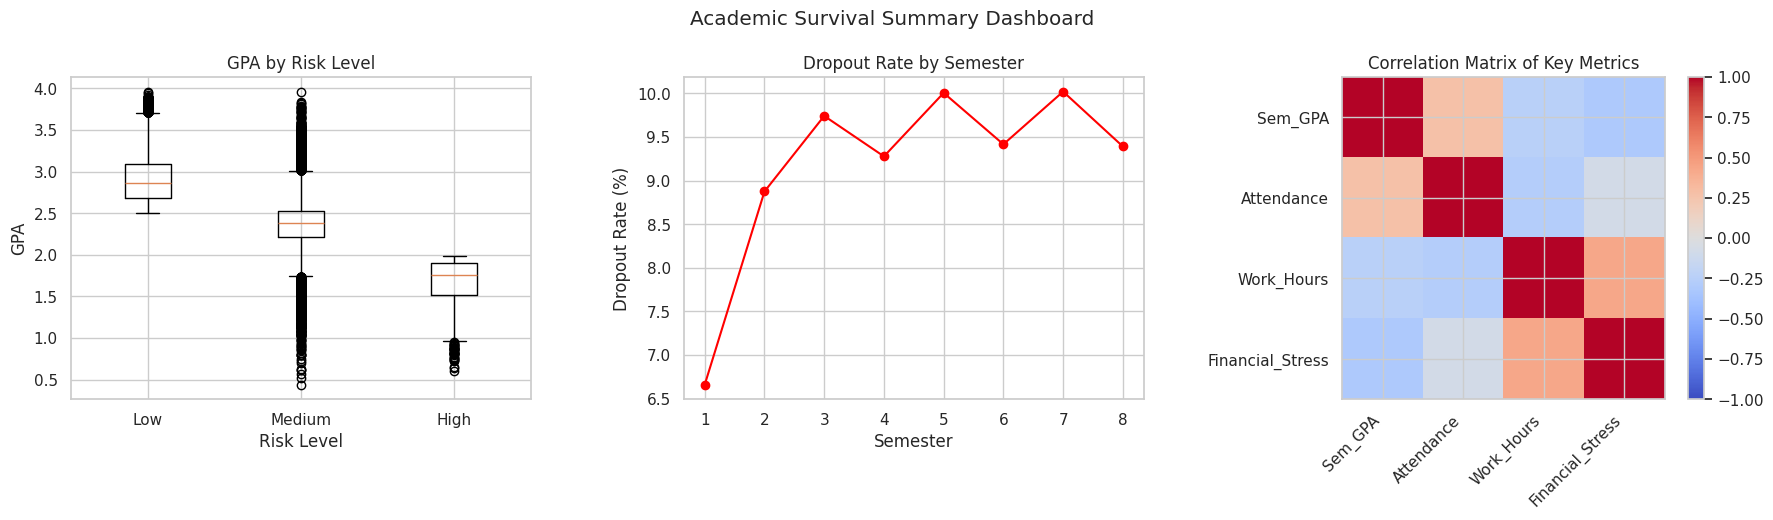

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
risk_levels = ['Low', 'Medium', 'High']
gpa_by_risk = [df[df['Risk_Level'] == r]['Sem_GPA'].values for r in risk_levels]
axes[0].boxplot(gpa_by_risk, tick_labels=risk_levels)
axes[0].set_title('GPA by Risk Level')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('GPA')
sem_dropout = df.groupby('Semester')['Is_Dropout'].mean() * 100
axes[1].plot(sem_dropout.index, sem_dropout.values, marker='o', color='red')
axes[1].set_title('Dropout Rate by Semester')
axes[1].set_xlabel('Semester')
axes[1].set_ylabel('Dropout Rate (%)')
corr_subset = df[['Sem_GPA', 'Attendance', 'Work_Hours', 'Financial_Stress']].corr().to_numpy()
im = axes[2].imshow(corr_subset, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[2])
keys = ['Sem_GPA', 'Attendance', 'Work_Hours', 'Financial_Stress']
axes[2].set_xticks(np.arange(len(keys)))
axes[2].set_yticks(np.arange(len(keys)))
axes[2].set_xticklabels(keys, rotation=45, ha='right')
axes[2].set_yticklabels(keys)
axes[2].set_title('Correlation Matrix of Key Metrics')
fig.suptitle('Academic Survival Summary Dashboard')
plt.tight_layout()
plt.show()

---
### End of Question Set
Bonus: write 3 insights you found about which students are most likely to drop out.